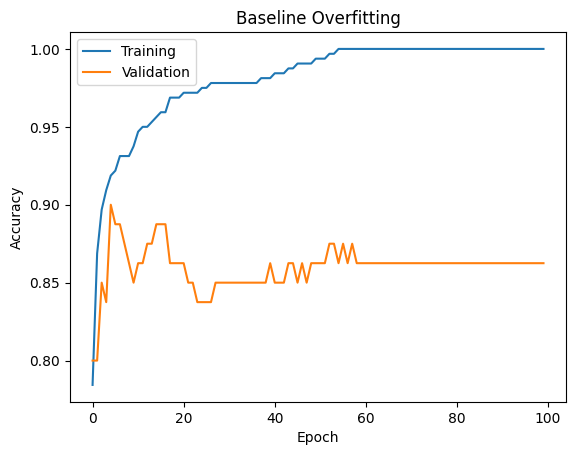

            Model  Train Accuracy  Test Accuracy  Train-Test Gap
0        Baseline           0.973           0.91           0.062
1        L2=0.001           0.973           0.91           0.062
2         L2=0.01           0.952           0.89           0.062
3          L2=0.1           0.905           0.92          -0.015
4     Dropout=0.2           0.973           0.90           0.073
5     Dropout=0.3           0.975           0.89           0.085
6     Dropout=0.5           0.960           0.92           0.040
7  Early Stopping           0.930           0.92           0.010


In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from tensorflow.keras import regularizers

np.random.seed(42)
tf.random.set_seed(42)

# Generate sample diabetes dataset
X, y = make_classification(
    n_samples=500, n_features=8, n_informative=5,
    n_redundant=1, random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Model creation
def build_model(l2=0, dropout=0):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(8,)),
        tf.keras.layers.Dense(
            128, activation='relu',
            kernel_regularizer=regularizers.l2(l2)
        ),
        tf.keras.layers.Dropout(dropout),
        tf.keras.layers.Dense(
            64, activation='relu',
            kernel_regularizer=regularizers.l2(l2)
        ),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

results = []

# Baseline, L2, Dropout and Early Stopping
experiments = [
    ('Baseline', 0, 0, False),
    ('L2=0.001', 0.001, 0, False),
    ('L2=0.01', 0.01, 0, False),
    ('L2=0.1', 0.1, 0, False),
    ('Dropout=0.2', 0, 0.2, False),
    ('Dropout=0.3', 0, 0.3, False),
    ('Dropout=0.5', 0, 0.5, False),
    ('Early Stopping', 0, 0, True)
]

for name, l2, drop, early in experiments:
    model = build_model(l2, drop)

    callbacks = []
    if early:
        callbacks = [tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True
        )]

    history = model.fit(
        X_train, y_train, epochs=100, batch_size=16,
        validation_split=0.2, callbacks=callbacks,
        verbose=0
    )

    train_acc = model.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = model.evaluate(X_test, y_test, verbose=0)[1]

    results.append([
        name, round(train_acc, 3),
        round(test_acc, 3),
        round(train_acc-test_acc, 3)
    ])

    if name == 'Baseline':
        plt.plot(history.history['accuracy'], label='Training')
        plt.plot(history.history['val_accuracy'], label='Validation')
        plt.title('Baseline Overfitting')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.show()

# Display comparison
table = pd.DataFrame(results, columns=[
    'Model', 'Train Accuracy', 'Test Accuracy', 'Train-Test Gap'
])
print(table)
